In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [19]:
df = pd.read_csv('exp_2_dataset_student_scores.csv')
print("First 5 rows:\n", df.head(), "\n")
print("Last 5 rows:\n", df.tail(), "\n")

First 5 rows:
    Hours  Scores
0    2.5      21
1    5.1      47
2    3.2      27
3    8.5      75
4    3.5      30 

Last 5 rows:
     Hours  Scores
20    2.7      30
21    4.8      54
22    3.8      35
23    6.9      76
24    7.8      86 



In [20]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=1/3, random_state=0)
print("\nTraining samples:", len(X_train), " Testing samples:", len(X_test))


Training samples: 16  Testing samples: 9


In [21]:
X = df.iloc[:, :-1].values
Y = df.iloc[:, -1].values
print("X (features):", X.flatten())
print("Y (targets):", Y)

X (features): [2.5 5.1 3.2 8.5 3.5 1.5 9.2 5.5 8.3 2.7 7.7 5.9 4.5 3.3 1.1 8.9 2.5 1.9
 6.1 7.4 2.7 4.8 3.8 6.9 7.8]
Y (targets): [21 47 27 75 30 20 88 60 81 25 85 62 41 42 17 95 30 24 67 69 30 54 35 76
 86]


In [22]:
regressor = LinearRegression()
regressor.fit(X_train, Y_train)

LinearRegression()

In [23]:
Y_pred = regressor.predict(X_test)
print("\nPredicted values:", np.round(Y_pred, 2))
print("Actual values   :", Y_test)


Predicted values: [17.04 33.52 74.22 26.73 59.68 39.33 20.92 78.09 69.37]
Actual values   : [20 27 69 30 62 35 24 86 76]


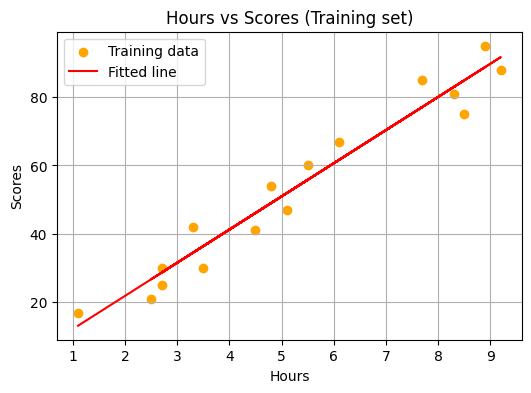

In [24]:
plt.figure(figsize=(6,4))
plt.scatter(X_train, Y_train, color="orange", label="Training data")
plt.plot(X_train, regressor.predict(X_train), color="red", label="Fitted line")
plt.title("Hours vs Scores (Training set)")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.legend()
plt.grid(True)
plt.show()

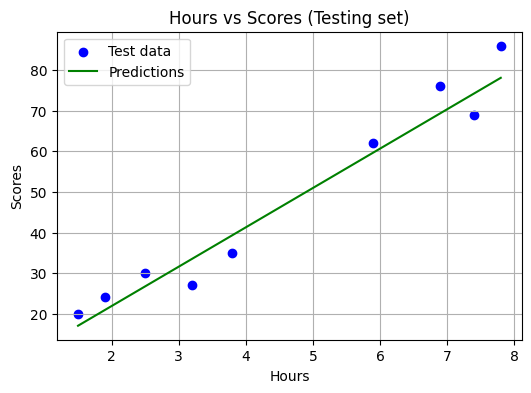

In [25]:
order = np.argsort(X_test.flatten())
X_test_sorted = X_test.flatten()[order]
Y_test_sorted = Y_test[order]
Y_pred_sorted = Y_pred[order]
plt.figure(figsize=(6,4))
plt.scatter(X_test, Y_test, color="blue", label="Test data")
plt.plot(X_test_sorted, Y_pred_sorted, color="green", label="Predictions")
plt.title("Hours vs Scores (Testing set)")
plt.xlabel("Hours")
plt.ylabel("Scores")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
print("\nMean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)


Mean Absolute Error (MAE): 4.691397441397446
Mean Squared Error (MSE): 25.463280738222593
Root Mean Squared Error (RMSE): 5.046115410711748


In [27]:
new_hours = np.array([[2.5], [8.0]])
pred_new = regressor.predict(new_hours)
print("\nPredictions for new hours", new_hours.flatten(), "=>", np.round(pred_new,2))


Predictions for new hours [2.5 8. ] => [26.73 80.03]
